In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from google.cloud import storage
import io

# ── config ────────────────────────────────────────────────────────────────────
BUCKET_NAME = "wildfire-irp-data-th25"
storage_client = storage.Client()
bucket = storage_client.bucket(BUCKET_NAME)

def load_npy_from_gcs(blob_name):
    blob = bucket.blob(blob_name)
    buf = io.BytesIO()
    blob.download_to_file(buf)
    buf.seek(0)
    return np.load(buf)

def list_blobs(prefix):
    return sorted([b.name for b in storage_client.list_blobs(BUCKET_NAME, prefix=prefix)])

# ── list what's in the bucket ─────────────────────────────────────────────────
goes_blobs  = list_blobs("processed_dataset/inputs/")
viirs_blobs = list_blobs("processed_dataset/ground_truth/")

print(f"GOES files  : {len(goes_blobs)}")
print(f"VIIRS files : {len(viirs_blobs)}")
for g, v in zip(goes_blobs, viirs_blobs):
    print(f"  {g.split('/')[-1]}  ←→  {v.split('/')[-1]}")

GOES files  : 14
VIIRS files : 14
  GOES_20191024_090500.npy  ←→  VIIRS_20191024_090500.npy
  GOES_20191024_104600.npy  ←→  VIIRS_20191024_104600.npy
  GOES_20191024_202700.npy  ←→  VIIRS_20191024_202700.npy
  GOES_20191024_220800.npy  ←→  VIIRS_20191024_220800.npy
  GOES_20191025_102700.npy  ←→  VIIRS_20191025_102700.npy
  GOES_20191025_200800.npy  ←→  VIIRS_20191025_200800.npy
  GOES_20191025_214900.npy  ←→  VIIRS_20191025_214900.npy
  GOES_20191026_100800.npy  ←→  VIIRS_20191026_100800.npy
  GOES_20191026_213000.npy  ←→  VIIRS_20191026_213000.npy
  GOES_20191027_094900.npy  ←→  VIIRS_20191027_094900.npy
  GOES_20191027_211100.npy  ←→  VIIRS_20191027_211100.npy
  GOES_20191028_093000.npy  ←→  VIIRS_20191028_093000.npy
  GOES_20191028_111100.npy  ←→  VIIRS_20191028_111100.npy
  GOES_20191028_205200.npy  ←→  VIIRS_20191028_205200.npy


In [2]:
# ── load one pair and inspect ─────────────────────────────────────────────────
IDX = 0   # change to check other pairs

goes  = load_npy_from_gcs(goes_blobs[IDX])
viirs = load_npy_from_gcs(viirs_blobs[IDX])

print(f"Pair: {goes_blobs[IDX].split('/')[-1]}")
print(f"  GOES  shape : {goes.shape},  dtype: {goes.dtype}")
print(f"  VIIRS shape : {viirs.shape}, dtype: {viirs.dtype}")
print(f"  GOES  range : [{np.nanmin(goes):.2f}, {np.nanmax(goes):.2f}]")
print(f"  VIIRS range : [{np.nanmin(viirs):.2f}, {np.nanmax(viirs):.2f}]")
print(f"  GOES  NaN % : {np.isnan(goes).mean()*100:.1f}%")
print(f"  VIIRS zeros : {(viirs == 0).mean()*100:.1f}%  (expected ~100% — placeholder)")

Pair: GOES_20191024_090500.npy
  GOES  shape : (8, 11),  dtype: float32
  VIIRS shape : (8, 11), dtype: float32
  GOES  range : [286.03, 386.02]
  VIIRS range : [0.00, 0.00]
  GOES  NaN % : 0.0%
  VIIRS zeros : 100.0%  (expected ~100% — placeholder)


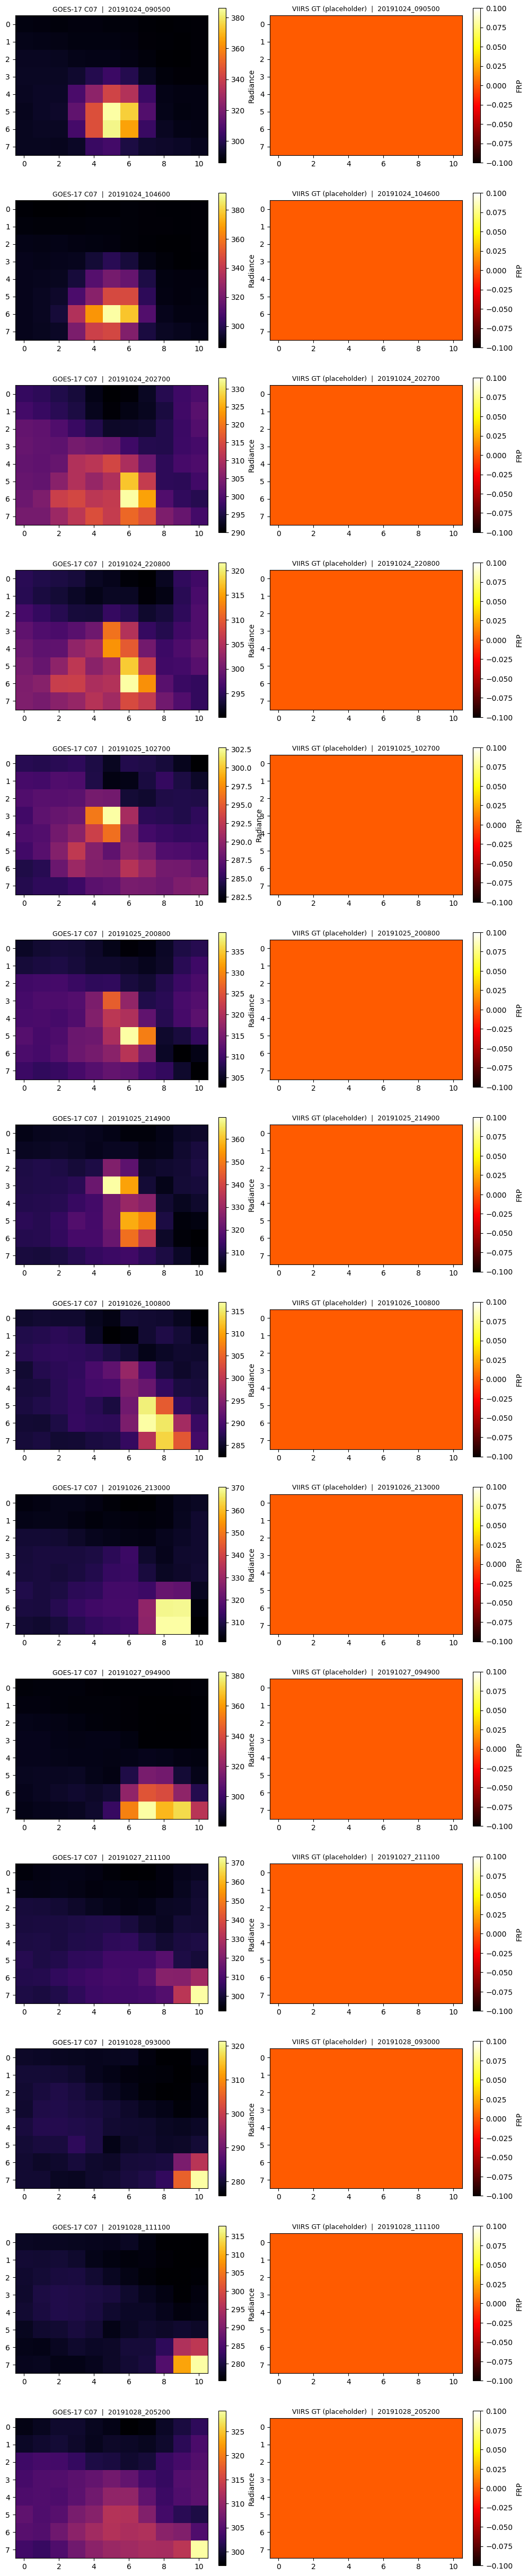

Saved: pair_overview.png


In [5]:
# ── visualise all pairs ───────────────────────────────────────────────────────
n = len(goes_blobs)
fig, axes = plt.subplots(n, 2, figsize=(10, 3.5 * n))
if n == 1:
    axes = [axes]

for i, (gb, vb) in enumerate(zip(goes_blobs, viirs_blobs)):
    goes  = load_npy_from_gcs(gb)
    viirs = load_npy_from_gcs(vb)
    
    ts = gb.split('/')[-1].replace('GOES_','').replace('.npy','')
    
    # GOES Channel 7 — raw radiance (W·m⁻²·sr⁻¹·μm⁻¹)
    im0 = axes[i][0].imshow(goes, cmap='inferno', origin='upper')
    axes[i][0].set_title(f"GOES-17 C07  |  {ts}", fontsize=9)
    plt.colorbar(im0, ax=axes[i][0], fraction=0.046, label='Radiance')

    # VIIRS placeholder — all zeros for now
    im1 = axes[i][1].imshow(viirs, cmap='hot', origin='upper')
    axes[i][1].set_title(f"VIIRS GT (placeholder)  |  {ts}", fontsize=9)
    plt.colorbar(im1, ax=axes[i][1], fraction=0.046, label='FRP')

plt.tight_layout()
plt.show()

In [6]:
goes = load_npy_from_gcs(goes_blobs[0])
print(goes.dtype)
print(np.unique(viirs))  # should be exactly [0.] or [0]

float32
[0.]
